# NYC taxi demand forecasting

Prepare daily features from all twelve months of 2024 yellow taxi rides.

In [1]:
from datetime import datetime, time
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

DATA_DIR = Path("../lab/data")
OUTPUT_PATH = Path("dataset.parquet")
MONTHS = range(1, 13)

MONEY_COLUMNS = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

## 1. Data reading

Read monthly Parquet files lazily and normalize timestamp units before concatenation. Keep data only from between 01.01.2024 and 31.12.2024.

In [2]:
input_columns = [
    "VendorID",
    "RatecodeID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "PULocationID",
    "DOLocationID",
    "payment_type",
    *MONEY_COLUMNS,
]

monthly_rides = [
    pl.scan_parquet(DATA_DIR / f"{month}.parquet")
    .select(input_columns)
    .with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("us"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("us"),
    )
    for month in MONTHS
]

rides = (
    pl.concat(monthly_rides, how="vertical_relaxed")
    .filter(
        pl.col("tpep_pickup_datetime") >= datetime(2024, 1, 1),
        pl.col("tpep_pickup_datetime") < datetime(2025, 1, 1),
        pl.col("tpep_dropoff_datetime") <= datetime(2025, 1, 1),
    )
    .with_columns(
        pl.col("VendorID", "RatecodeID", "payment_type").cast(pl.UInt8, strict=False),
        pl.col("PULocationID", "DOLocationID").cast(pl.UInt16, strict=False),
    )
)

zones = pl.read_csv(DATA_DIR / "taxi_zone_lookup.csv").select(
    pl.col("LocationID").cast(pl.UInt16),
    pl.col("Borough").fill_null("Unknown").cast(pl.Categorical),
)

In [3]:
rides.collect_schema()

Schema([('VendorID', UInt8),
        ('RatecodeID', UInt8),
        ('tpep_pickup_datetime', Datetime(time_unit='us', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='us', time_zone=None)),
        ('passenger_count', Int64),
        ('trip_distance', Float64),
        ('PULocationID', UInt16),
        ('DOLocationID', UInt16),
        ('payment_type', UInt8),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

## 2. Data cleaning and filtering
- fill NULL values in passengers_count with 1
- remove rides with zero passengers
- if a ride has over 6 passengers, replace the value with 6
- remove rides lasting over 2 hours
- in all money-related columns, replace values with absolute value to fix negative amounts
- remove rides with over 1000 dollars in any money-related column
- remove rows with values of RatecodeID or VendorID missing or outside those defined in the data dictionary

In [4]:
VALID_VENDOR_IDS = [1, 2, 6, 7]
VALID_RATE_CODES = [1, 2, 3, 4, 5, 6, 99]


def clean_rides(frame):
    duration = pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime")

    return frame.with_columns(
        pl.col("passenger_count")
        .fill_null(1)
        .clip(upper_bound=6)
        .cast(pl.UInt8, strict=False),
        pl.col(MONEY_COLUMNS).abs(),
    ).filter(
        pl.col("passenger_count") > 0,
        duration.is_between(pl.duration(seconds=0), pl.duration(hours=2)),
        pl.col("VendorID").is_in(VALID_VENDOR_IDS),
        pl.col("RatecodeID").is_in(VALID_RATE_CODES),
        pl.all_horizontal(
            (pl.col(name) <= 1000) | pl.col(name).is_null() for name in MONEY_COLUMNS
        ),
    )

## 3. Data transformation

- combine payment type values for "No charge", "Dispute", "Unknown" and "Voided trip" into one type, so we have only credit card, cash, or other
- replace PULocationID and DOLocationID with borough names by joining taxi zone lookup and removing unnecessary columns
- add boolean variable is_airport_ride, true if there is non-zero airport fee
-add boolean variable is_rush_hour, rush hours are defined as 6:30–9:30 and 15:30-20:00 during weekdays

In [5]:
PAYMENT_TYPES = ["card", "cash", "other"]

pickup_zones = zones.rename(
    {"LocationID": "PULocationID", "Borough": "pickup_borough"}
).lazy()
dropoff_zones = zones.rename(
    {"LocationID": "DOLocationID", "Borough": "dropoff_borough"}
).lazy()


def transform_rides(frame):
    pickup = pl.col("tpep_pickup_datetime")
    pickup_time = pickup.dt.time()
    rush_hour = (pickup.dt.weekday() <= 5) & (
        pickup_time.is_between(time(6, 30), time(9, 30))
        | pickup_time.is_between(time(15, 30), time(20, 0))
    )

    return (
        frame.join(pickup_zones, on="PULocationID", how="left", validate="m:1")
        .join(dropoff_zones, on="DOLocationID", how="left", validate="m:1")
        .with_columns(
            pl.col("payment_type")
            .replace_strict({1: "card", 2: "cash"}, default="other")
            .cast(pl.Enum(PAYMENT_TYPES)),
            pl.col("pickup_borough", "dropoff_borough").fill_null("Unknown"),
            (pl.col("Airport_fee").fill_null(0) != 0).alias("is_airport_ride"),
            rush_hour.alias("is_rush_hour"),
            pickup.dt.date().alias("date"),
        )
        .select(
            "date",
            "payment_type",
            "pickup_borough",
            "dropoff_borough",
            "is_airport_ride",
            "is_rush_hour",
            "fare_amount",
            "trip_distance",
            "total_amount",
            "congestion_surcharge",
            "passenger_count",
        )
    )

## 4. Feature extraction

- Apply dummy encoding to features:
  - Payment type
  - Pickup borough
  - Dropoff borough

- Add integer variables for counting daily events:
  - Total number of rides (target variable)
  - Number of airport rides
  - Number of rush hour rides

- Add features aggregating daily rides information:
  - Average fare amount
  - Median distance
  - Sum of total amounts
  - Total amount paid by card, cash, and other
  - Total congestion surcharge
  - Total number of passengers

- Add time features:
  - quarter
  - month
  - day_of_month
  - day_of_week
  - is_weekend (boolean)

- Add column date, indicating day with given features
- Make sure to exclude other columns, unnecessary for machine learning, e.g. IDs, timestamps, unused financial information
- Properly name all columns
- Save results as dataset.parquet file

In [9]:
borough_names = sorted(set(zones["Borough"].to_list()) | {"Unknown"})

dummy_expressions = [
    (pl.col("payment_type") == payment).cast(pl.UInt8).alias(f"payment_{payment}_count")
    for payment in PAYMENT_TYPES
]

for column in ["pickup_borough", "dropoff_borough"]:
    for borough in borough_names:
        suffix = borough.lower().replace(" ", "_").replace("/", "_")
        dummy_expressions.append(
            (pl.col(column) == borough).cast(pl.UInt8).alias(f"{column}_{suffix}_count")
        )

dummy_columns = [expr.meta.output_name() for expr in dummy_expressions]

In [10]:
daily_aggregations = [
    pl.len().cast(pl.UInt32).alias("ride_count"),
    pl.col("is_airport_ride").cast(pl.UInt32).sum().alias("airport_ride_count"),
    pl.col("is_rush_hour").cast(pl.UInt32).sum().alias("rush_hour_ride_count"),
    pl.col("fare_amount").mean().alias("avg_fare_amount"),
    pl.col("trip_distance").median().alias("median_trip_distance"),
    pl.col("total_amount").sum().alias("total_amount_sum"),
    *[
        pl.col("total_amount")
        .filter(pl.col("payment_type") == payment)
        .sum()
        .alias(f"{payment}_amount_sum")
        for payment in PAYMENT_TYPES
    ],
    pl.col("congestion_surcharge").sum().alias("congestion_surcharge_sum"),
    pl.col("passenger_count").cast(pl.UInt32).sum().alias("passenger_count_sum"),
    *[pl.col(name).cast(pl.UInt32).sum().alias(name) for name in dummy_columns],
]

time_features = [
    pl.col("date").dt.quarter().cast(pl.UInt8).alias("quarter"),
    pl.col("date").dt.month().cast(pl.UInt8).alias("month"),
    pl.col("date").dt.day().cast(pl.UInt8).alias("day_of_month"),
    pl.col("date").dt.weekday().cast(pl.UInt8).alias("day_of_week"),
    (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
]

Combine pipeline

In [11]:
daily_dataset = (
    rides.pipe(clean_rides)
    .pipe(transform_rides)
    .with_columns(dummy_expressions)
    .group_by("date")
    .agg(daily_aggregations)
    .with_columns(time_features)
    .sort("date")
)

daily_dataset.sink_parquet(OUTPUT_PATH, compression="zstd")
dataset = pl.read_parquet(OUTPUT_PATH)

## 5. Data analysis

Inspect the shape, first rows, summary statistics, and schema of the daily dataset.

In [12]:
print(dataset.shape)
dataset.head()

(366, 36)


date,ride_count,airport_ride_count,rush_hour_ride_count,avg_fare_amount,median_trip_distance,total_amount_sum,card_amount_sum,cash_amount_sum,other_amount_sum,congestion_surcharge_sum,passenger_count_sum,payment_card_count,payment_cash_count,payment_other_count,pickup_borough_bronx_count,pickup_borough_brooklyn_count,pickup_borough_ewr_count,pickup_borough_manhattan_count,pickup_borough_n_a_count,pickup_borough_queens_count,pickup_borough_staten_island_count,pickup_borough_unknown_count,dropoff_borough_bronx_count,dropoff_borough_brooklyn_count,dropoff_borough_ewr_count,dropoff_borough_manhattan_count,dropoff_borough_n_a_count,dropoff_borough_queens_count,dropoff_borough_staten_island_count,dropoff_borough_unknown_count,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,f64,f64,f64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u8,u8,u8,u8,bool
2024-01-01,69665,8352,19398,22.217628,2.09,2.1849e6,1.7445e6,384662.67,55778.86,156123.25,109137,52970,14491,2204,82,664,21,59261,93,9270,3,271,583,3825,388,58606,605,5183,31,444,1,1,1,1,false
2024-01-02,72582,9828,31014,21.501214,1.82,2.2500e6,1.8023e6,396334.47,51441.03,160615.0,104070,55173,15387,2022,167,684,20,60492,54,10897,2,266,555,3411,319,62613,437,4830,32,385,1,1,2,2,false
2024-01-03,79566,9140,33389,20.170854,1.75,2.3320e6,1.8662e6,416241.57,49554.25,177985.0,110973,61343,16202,2021,228,679,16,68074,36,10217,1,315,640,3464,282,69706,398,4589,14,473,1,1,3,3,false
2024-01-04,99075,8270,43572,18.865887,1.75,2760297.9,2.2558e6,444631.77,59823.2,226627.5,135813,78736,17994,2345,244,665,10,88459,40,9271,1,385,757,3461,226,89107,346,4615,14,549,1,1,4,4,false
2024-01-05,98859,7460,40518,18.246842,1.7,2.6767e6,2.1982e6,420698.52,57798.23,227542.5,137165,78700,17699,2460,183,605,8,89232,37,8399,1,394,651,3181,222,89459,345,4373,20,608,1,1,5,5,false


In [13]:
dataset.describe()

statistic,date,ride_count,airport_ride_count,rush_hour_ride_count,avg_fare_amount,median_trip_distance,total_amount_sum,card_amount_sum,cash_amount_sum,other_amount_sum,congestion_surcharge_sum,passenger_count_sum,payment_card_count,payment_cash_count,payment_other_count,pickup_borough_bronx_count,pickup_borough_brooklyn_count,pickup_borough_ewr_count,pickup_borough_manhattan_count,pickup_borough_n_a_count,pickup_borough_queens_count,pickup_borough_staten_island_count,pickup_borough_unknown_count,dropoff_borough_bronx_count,dropoff_borough_brooklyn_count,dropoff_borough_ewr_count,dropoff_borough_manhattan_count,dropoff_borough_n_a_count,dropoff_borough_queens_count,dropoff_borough_staten_island_count,dropoff_borough_unknown_count,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100093.606557,8977.778689,29942.142077,19.952261,1.718634,2.9110e6,2.4606e6,372223.630328,78152.278033,230198.157158,134956.081967,82238.480874,14923.278689,2931.846995,206.032787,881.948087,15.983607,88507.68306,60.18306,10106.571038,2.579235,312.625683,589.969945,4008.297814,284.52459,89040.204918,484.598361,5211.882514,25.251366,448.877049,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15371.624598,1716.338555,19694.134665,1.204555,0.10091,461485.581552,428815.031564,36193.567937,17262.182208,37863.610575,18722.722417,14160.413403,1357.366862,554.182393,51.138641,201.753668,7.71263,15153.93754,18.122773,1764.927622,1.735371,57.290409,67.96076,581.624147,73.624208,14677.47809,93.722002,689.139555,6.752549,92.052508,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47390.0,3355.0,0.0,16.676264,1.5,1.3260e6,996577.34,240633.43,41303.84,107825.0,74198.0,34052.0,10244.0,1656.0,48.0,298.0,2.0,41757.0,23.0,4935.0,0.0,149.0,370.0,1831.0,122.0,41657.0,261.0,2826.0,9.0,192.0,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89572.0,7869.0,0.0,19.125929,1.66,2.5817e6,2.1701e6,352429.45,65781.9,203501.0,122218.0,72543.0,14109.0,2566.0,166.0,731.0,10.0,77349.0,46.0,8861.0,1.0,273.0,544.0,3682.0,236.0,78535.0,418.0,4773.0,20.0,390.0,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100781.0,9018.0,39519.0,19.950705,1.7,2.9164e6,2.4629e6,375884.77,79217.11,232817.5,134077.0,83418.0,14966.0,2910.0,216.0,938.0,15.0,89891.0,59.0,10072.0,2.0,310.0,591.0,4009.0,275.0,90291.0,481.0,5251.0,25.0,444.0,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110799.0,10144.0,44782.0,20.713722,1.77,3.2228e6,2.7450e6,398461.95,90279.69,256939.5,147187.0,91738.0,15833.0,3271.0,243.0,1019.0,20.0,99601.0,70.0,11253.0,3.0,347.0,639.0,4378.0,335.0,99446.0,549.0,5703.0,30.0,515.0,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141677.0,14903.0,56568.0,24.447593,2.2,4.4621e6,3.9163e6,449948.51,123894.72,330475.0,199440.0,120976.0,17994.0,4596.0,323.0,1673.0,47.0,128160.0,125.0,16176.0,8.0,505.0,801.0,6236.0,583.0,127687.0,716.0,6851.0,51.0,718.0,4.0,12.0,31.0,7.0,1.0


In [14]:
print(dataset.schema)

Schema({'date': Date, 'ride_count': UInt32, 'airport_ride_count': UInt32, 'rush_hour_ride_count': UInt32, 'avg_fare_amount': Float64, 'median_trip_distance': Float64, 'total_amount_sum': Float64, 'card_amount_sum': Float64, 'cash_amount_sum': Float64, 'other_amount_sum': Float64, 'congestion_surcharge_sum': Float64, 'passenger_count_sum': UInt32, 'payment_card_count': UInt32, 'payment_cash_count': UInt32, 'payment_other_count': UInt32, 'pickup_borough_bronx_count': UInt32, 'pickup_borough_brooklyn_count': UInt32, 'pickup_borough_ewr_count': UInt32, 'pickup_borough_manhattan_count': UInt32, 'pickup_borough_n_a_count': UInt32, 'pickup_borough_queens_count': UInt32, 'pickup_borough_staten_island_count': UInt32, 'pickup_borough_unknown_count': UInt32, 'dropoff_borough_bronx_count': UInt32, 'dropoff_borough_brooklyn_count': UInt32, 'dropoff_borough_ewr_count': UInt32, 'dropoff_borough_manhattan_count': UInt32, 'dropoff_borough_n_a_count': UInt32, 'dropoff_borough_queens_count': UInt32, 'dro

##### 5.1 Distribution of daily ride counts

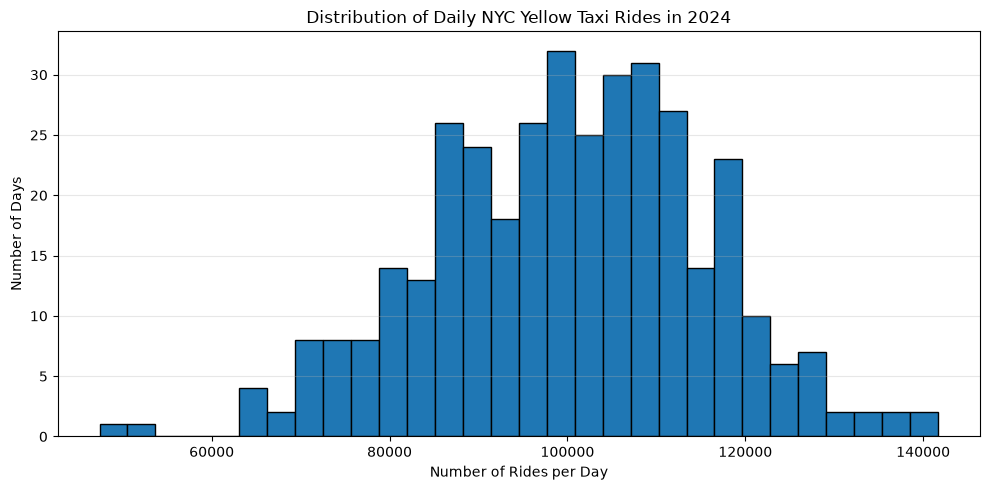

In [15]:
plt.figure(figsize=(10, 5))
plt.hist(dataset["ride_count"].to_numpy(), bins=30, edgecolor="black")
plt.title("Distribution of Daily NYC Yellow Taxi Rides in 2024")
plt.xlabel("Number of Rides per Day")
plt.ylabel("Number of Days")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### 5.2 Daily ride counts over time

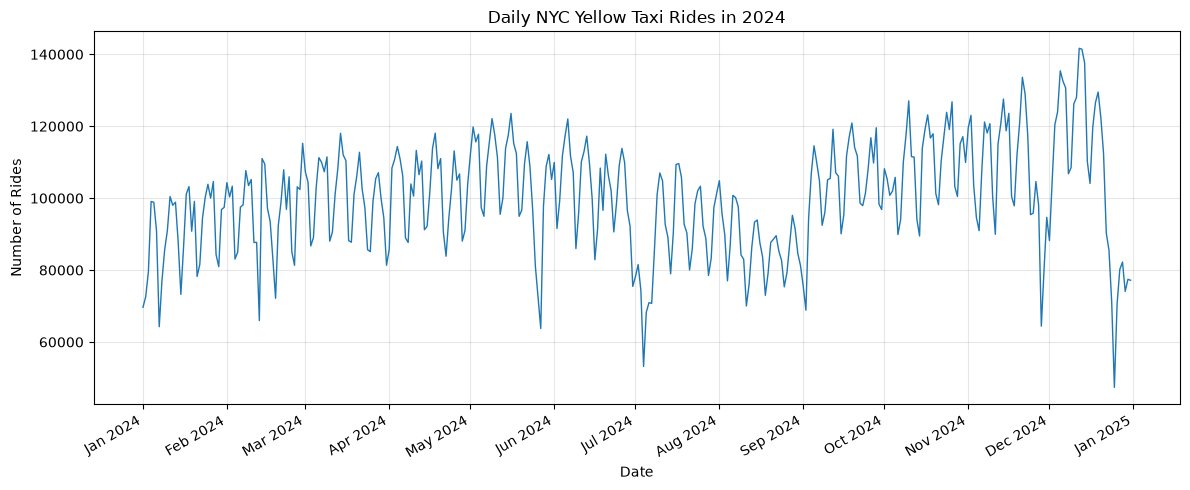

In [16]:
plot_data = dataset.sort("date").to_pandas()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(plot_data["date"], plot_data["ride_count"], linewidth=1)
ax.set_title("Daily NYC Yellow Taxi Rides in 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Rides")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()